3. سوالات تکلیف

In [28]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

import matplotlib.pyplot as plt
import pandas as pd


sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_moons_data, get_mnist_data, get_mnist_data_with_noise, NoisyMNIST

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


3-4 الگوریتم های بهینه سازی پیشرفته (روی mnist)

3-4-1 SGD با ممنتوم، AdaGrad، RMSProp و Adam را روی یک معماری ثابت (مثلا دو لایه مخفی 128 و 64 نرون) ﺑﺮﺍﻱ ﺩﺳﺘﻪ ﺑﻨﺪﻱ MNIST (10 کلاس) ﻣﻘﺎﻳﺴﻪ ﻛﻨﻴﺪ. ﻧﺮﺥ ﻳﺎﺩﮔﻴﺮﻱ ﺍﻭﻟﻴﻪ ﺭﺍ ﺑﺮﺍﻱ ﻫﺮ ﺑﻬﻴﻨﻪ ﺳﺎﺯ ﺑﻪ ﻃﻮﺭ ﺟﺪﺍﮔﺎﻧﻪ ﺑﺎ ﺁﺯﻣﻮﻥ ﻭ ﺧﻄﺎ ﺑﻴﺎﺑﻴﺪ.

الف) ﺟﺪﻭﻟﻲ ﺗﻬﻴﻪ ﻛﻨﻴﺪ ﺷﺎﻣﻞ: ﺑﻬﻴﻨﻪ ﺳﺎﺯ، ﻧﺮﺥ ﻳﺎﺩﮔﻴﺮﻱ ﺑﻬﻴﻨﻪ، ﺩﻗﺖ ﺁﺯﻣﻮﻥ ﻧﻬﺎﻳﻲ، ﺗﻌﺪﺍﺩ ﺩﻭﺭﻩ ﺗﺎ ﺭﺳﻴﺪﻥ ﺑﻪ ﺩﻗﺖ ۹۰%.

ب) ﻧﻤﻮﺩﺍﺭ ﺩﻗﺖ ﺁﺯﻣﻮﻥ ﺩﺭ ﺑﺮﺍﺑﺮ ﺩﻭﺭﻩ ﺭﺍ ﺑﺮﺍﻱ ﻫﻤﻪ ﻱ ﺑﻬﻴﻨﻪ ﺳﺎﺯﻫﺎ ﺑﺎ ﺑﻬﺘﺮﻳﻦ ﻧﺮﺥ ﻳﺎﺩﮔﻴﺮﻱ ﺭﺳﻢ ﻛﻨﻴﺪ.

پ) ﻛﺪﺍﻡ ﺑﻬﻴﻨﻪ ﺳﺎﺯ ﺳﺮﻳﻊ ﺗﺮﻳﻦ ﻫﻤﮕﺮﺍﻳﻲ ﻭ ﻛﺪﺍﻡ ﺑﻬﺘﺮﻳﻦ ﺩﻗﺖ ﻧﻬﺎﻳﻲ ﺭﺍ ﺩﺍﺭﺩ؟



In [2]:
class TwoLayerMLP(nn.Module):
    def __init__(self, input_dim=784, hidden1=128, hidden2=64, num_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.relu2 = nn.ReLU()
        self.out = nn.Linear(hidden2, num_classes)
    
    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.out(x)


In [3]:
def train_and_evaluate(model, trainloader, testloader, optimizer_name, lr, momentum=0.9, epochs=30, device='cuda'):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    
    if optimizer_name == 'SGD_momentum':
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    elif optimizer_name == 'AdaGrad':
        optimizer = optim.Adagrad(model.parameters(), lr=lr)
    elif optimizer_name == 'RMSProp':
        optimizer = optim.RMSprop(model.parameters(), lr=lr)
    elif optimizer_name == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=lr)
    else:
        raise ValueError(f"Unknown optimizer: {optimizer_name}")
    
    test_accs = []
    epoch_to_90 = None
    
    for epoch in range(epochs):
        model.train()
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
        
        # ارزیابی روی تست
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in testloader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        acc = 100 * correct / total
        test_accs.append(acc)
        
        # بررسی رسیدن به 90%
        if epoch_to_90 is None and acc >= 90.0:
            epoch_to_90 = epoch + 1
        
        if (epoch+1) % 5 == 0:
            print(f"{optimizer_name:12s} | Epoch {epoch+1:2d} | Test Acc: {acc:.2f}%")
    
    return test_accs, epoch_to_90


In [ ]:
def find_best_lr(optimizer_name, trainloader, testloader, lr_candidates, device='cuda'):
    best_lr = None
    best_acc = 0
    best_accs_history = None
    best_epoch_to_90 = None
    
    for lr in lr_candidates:
        print(f"\nTesting {optimizer_name} with lr={lr}")
        model = TwoLayerMLP()
        accs_history, epoch_to_90 = train_and_evaluate(model, trainloader, testloader, optimizer_name, lr, epochs=25, device=device)
        final_acc = accs_history[-1]
        if final_acc > best_acc:
            best_acc = final_acc
            best_lr = lr
            best_accs_history = accs_history
            best_epoch_to_90 = epoch_to_90
            if epoch_to_90 is None:
                epoch_to_90 = '-'
    print(f"Best for {optimizer_name}: lr={best_lr}, final acc={best_acc:.2f}%, epoch to 90%={best_epoch_to_90}")
    return best_lr, best_accs_history, best_acc, best_epoch_to_90


In [5]:
X_train, X_test, y_train, y_test, trainloader, testloader = get_mnist_data(batch_size=64)

In [6]:

device = 'cuda' if torch.cuda.is_available() else 'cpu'

optimizers = {
	'SGD_momentum': [0.001, 0.005, 0.01, 0.1],
	'AdaGrad': [0.001, 0.005, 0.01, 0.1],
	'RMSProp': [0.001, 0.005, 0.01, 0.1],
	'Adam': [0.0001, 0.005, 0.01, 0.1]
}

results = {}  # نام بهینه‌ساز -> (best_lr, acc_history, final_acc, epoch_to_90)
for opt_name, lr_list in optimizers.items():
	best_lr, acc_hist, final_acc, epoch_90 = find_best_lr(
		opt_name, trainloader, testloader, lr_list, device=device
	)
	results[opt_name] = (best_lr, acc_hist, final_acc, epoch_90)



Testing SGD_momentum with lr=0.001
SGD_momentum | Epoch  5 | Test Acc: 94.71%
SGD_momentum | Epoch 10 | Test Acc: 96.48%
SGD_momentum | Epoch 15 | Test Acc: 97.05%
SGD_momentum | Epoch 20 | Test Acc: 97.39%
SGD_momentum | Epoch 25 | Test Acc: 97.55%

Testing SGD_momentum with lr=0.005
SGD_momentum | Epoch  5 | Test Acc: 97.33%
SGD_momentum | Epoch 10 | Test Acc: 97.81%
SGD_momentum | Epoch 15 | Test Acc: 97.99%
SGD_momentum | Epoch 20 | Test Acc: 98.01%
SGD_momentum | Epoch 25 | Test Acc: 98.05%

Testing SGD_momentum with lr=0.01
SGD_momentum | Epoch  5 | Test Acc: 97.68%
SGD_momentum | Epoch 10 | Test Acc: 97.92%
SGD_momentum | Epoch 15 | Test Acc: 98.10%
SGD_momentum | Epoch 20 | Test Acc: 98.09%
SGD_momentum | Epoch 25 | Test Acc: 98.14%

Testing SGD_momentum with lr=0.1
SGD_momentum | Epoch  5 | Test Acc: 95.05%
SGD_momentum | Epoch 10 | Test Acc: 94.70%
SGD_momentum | Epoch 15 | Test Acc: 11.35%
SGD_momentum | Epoch 20 | Test Acc: 11.35%
SGD_momentum | Epoch 25 | Test Acc: 9.58%


In [7]:

# --------------------------------------------------------
# (الف) جدول نتایج
# --------------------------------------------------------
print("\n" + "="*60)
print("Table of Results (a)")
print("-"*60)
print(f"{'Optimizer':<15} {'Best LR':<12} {'Final Test Acc (%)':<20} {'Epochs to 90%':<15}")
for opt_name, (lr, _, acc, ep90) in results.items():
	ep90_str = str(ep90) if ep90 is not None else '>30'
	print(f"{opt_name:<15} {lr:<12} {acc:<20.2f} {ep90_str:<15}")



Table of Results (a)
------------------------------------------------------------
Optimizer       Best LR      Final Test Acc (%)   Epochs to 90%  
SGD_momentum    0.01         98.14                1              
AdaGrad         0.01         97.97                1              
RMSProp         0.001        97.97                1              
Adam            0.0001       97.75                1              


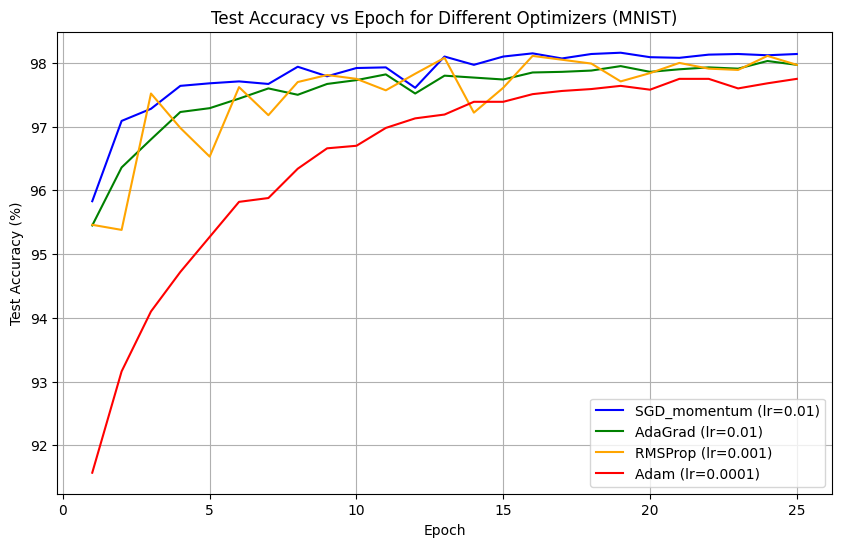

In [8]:

# --------------------------------------------------------
# (ب) نمودار دقت آزمون در برابر دوره برای بهترین نرخ هر بهینه‌ساز
# --------------------------------------------------------
plt.figure(figsize=(10, 6))
colors = {'SGD_momentum': 'blue', 'AdaGrad': 'green', 'RMSProp': 'orange', 'Adam': 'red'}
for opt_name, (lr, acc_hist, final_acc, ep90) in results.items():
	plt.plot(range(1, len(acc_hist)+1), acc_hist, label=f"{opt_name} (lr={lr})", color=colors.get(opt_name))
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.title('Test Accuracy vs Epoch for Different Optimizers (MNIST)')
plt.legend()
plt.grid(True)
plt.savefig('optimizers_comparison.png', dpi=150)
plt.show()


In [9]:

# --------------------------------------------------------
# (پ) پاسخ: سریع‌ترین همگرایی و بهترین دقت نهایی
# --------------------------------------------------------
# یافتن سریع‌ترین همگرایی (کمترین دوره تا 90%)
fastest = min((ep90 for _, (_, _, _, ep90) in results.items() if ep90 is not None), default=None)
# یافتن بهترین دقت نهایی
best_acc = max(final_acc for _, (_, _, final_acc, _) in results.items())

print("\n" + "="*60)
print("Answers (c):")
print(f"Fastest convergence to 90%: {[name for name,(_,_,_,ep90) in results.items() if ep90 == fastest][0]} with {fastest} epochs")
print(f"Best final test accuracy: {[name for name,(_,_,final_acc,_) in results.items() if final_acc == best_acc][0]} with {best_acc:.2f}%")



Answers (c):
Fastest convergence to 90%: SGD_momentum with 1 epochs
Best final test accuracy: SGD_momentum with 98.14%


3-4-2 ﺗﺄﺛﻴﺮ ﻧﺮﺥ ﻳﺎﺩﮔﻴﺮﻱ ﺩﺭ Adam: ﺑﺮﺍﻱ  Adam، ﻣﻘﺎﺩﻳﺮ ﻣﺨﺘﻠﻒ ﻧﺮﺥ یادگیری (10^-5, 10^-4, 10^-3, 10^-2, 10^-1) رﺍ ﺁﺯﻣﺎﻳﺶ ﻛﻨﻴﺪ ﻭ ﺩﻗﺖ ﺁﺯﻣﻮﻥ ﺭﺍ ﮔﺰﺍﺭﺵ ﺩﻫﻴﺪ.

In [10]:
class TwoLayerMLP(nn.Module):
    def __init__(self, input_dim=784, hidden1=128, hidden2=64, num_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.relu2 = nn.ReLU()
        self.out = nn.Linear(hidden2, num_classes)
    
    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.out(x)


In [11]:
def train_adam_with_lr(lr, trainloader, testloader, epochs=20, device='cuda'):
    model = TwoLayerMLP().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    test_accs = []
    for epoch in range(epochs):
        model.train()
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
        
        # ارزیابی روی تست
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in testloader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        acc = 100 * correct / total
        test_accs.append(acc)
        
        if (epoch+1) % 5 == 0:
            print(f"lr={lr:8} | Epoch {epoch+1:2d} | Test Acc: {acc:.2f}%")
    return test_accs


In [12]:
X_train, X_test, y_train, y_test, trainloader, testloader = get_mnist_data(batch_size=64)

In [13]:

device = 'cuda' if torch.cuda.is_available() else 'cpu'

learning_rates = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
results = {}

for lr in learning_rates:
	print(f"\n--- Testing Adam with learning rate = {lr} ---")
	acc_hist = train_adam_with_lr(lr, trainloader, testloader, epochs=20, device=device)
	results[lr] = acc_hist



--- Testing Adam with learning rate = 1e-05 ---
lr=   1e-05 | Epoch  5 | Test Acc: 90.01%
lr=   1e-05 | Epoch 10 | Test Acc: 91.80%
lr=   1e-05 | Epoch 15 | Test Acc: 92.59%
lr=   1e-05 | Epoch 20 | Test Acc: 93.13%

--- Testing Adam with learning rate = 0.0001 ---
lr=  0.0001 | Epoch  5 | Test Acc: 95.53%
lr=  0.0001 | Epoch 10 | Test Acc: 96.94%
lr=  0.0001 | Epoch 15 | Test Acc: 97.44%
lr=  0.0001 | Epoch 20 | Test Acc: 97.67%

--- Testing Adam with learning rate = 0.001 ---
lr=   0.001 | Epoch  5 | Test Acc: 97.09%
lr=   0.001 | Epoch 10 | Test Acc: 97.56%
lr=   0.001 | Epoch 15 | Test Acc: 97.58%
lr=   0.001 | Epoch 20 | Test Acc: 97.69%

--- Testing Adam with learning rate = 0.01 ---
lr=    0.01 | Epoch  5 | Test Acc: 95.37%
lr=    0.01 | Epoch 10 | Test Acc: 96.25%
lr=    0.01 | Epoch 15 | Test Acc: 96.63%
lr=    0.01 | Epoch 20 | Test Acc: 96.33%

--- Testing Adam with learning rate = 0.1 ---
lr=     0.1 | Epoch  5 | Test Acc: 11.35%
lr=     0.1 | Epoch 10 | Test Acc: 11.35%
l

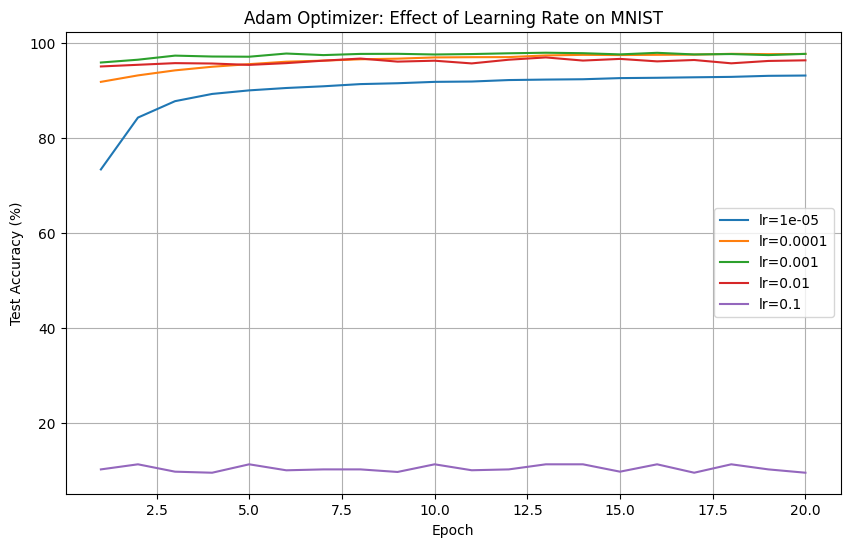


=== Final Test Accuracy after 20 epochs ===
Learning rate =    1e-05 -> Final Accuracy: 93.13%
Learning rate =   0.0001 -> Final Accuracy: 97.67%
Learning rate =    0.001 -> Final Accuracy: 97.69%
Learning rate =     0.01 -> Final Accuracy: 96.33%
Learning rate =      0.1 -> Final Accuracy: 9.58%


In [14]:

plt.figure(figsize=(10,6))
for lr, accs in results.items():
	plt.plot(range(1, len(accs)+1), accs, label=f'lr={lr}')
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.title('Adam Optimizer: Effect of Learning Rate on MNIST')
plt.legend()
plt.grid(True)
plt.savefig('adam_lr_effect.png', dpi=150)
plt.show()

print("\n=== Final Test Accuracy after 20 epochs ===")
for lr, accs in results.items():
	print(f"Learning rate = {lr:8} -> Final Accuracy: {accs[-1]:.2f}%")


3-4-3 ﻣﻘﺎﻳﺴﻪ ﺭﻭﻱ ﺩﺍﺩﻩ ﻱ ﻧﻮﻳﺰﻱ: ﺑﻪ ﺩﺍﺩﻩ ﻱ MNIST ﻧﻮﻳﺰ ﮔﺎﻭﺳﻲ ﺑﺎ ﺍﻧﺤﺮﺍﻑ 0.5 ﺍﺿﺎﻓﻪ ﻛﻨﻴﺪ. ﻣﺪﻝ ﺭﺍ ﺑﺎ ﺑﻬﺘﺮﻳﻦ ﭘﻴﻜﺮﺑﻨﺪﻱ ﻫﺮ ﺑﻬﻴﻨﻪ ﺳﺎﺯ ﺩﻭﺑﺎﺭﻩ ﺁﻣﻮﺯﺵ ﺩﻫﻴﺪ. ﻛﺪﺍﻡ ﺑﻬﻴﻨﻪ ﺳﺎﺯ ﻋﻤﻠﻜﺮﺩ ﺧﻮﺩ ﺭﺍ ﻛﻤﺘﺮ ﺍﺯ ﺩﺳﺖ میدهد؟

In [16]:
class TwoLayerMLP(nn.Module):
    def __init__(self, input_dim=784, hidden1=128, hidden2=64, num_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.relu2 = nn.ReLU()
        self.out = nn.Linear(hidden2, num_classes)
    
    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.out(x)


In [17]:
def evaluate_optimizer_on_noisy(optimizer_name, best_lr, trainloader, testloader, epochs=20, device='cuda'):
    model = TwoLayerMLP().to(device)
    criterion = nn.CrossEntropyLoss()
    if optimizer_name == 'SGD_momentum':
        optimizer = optim.SGD(model.parameters(), lr=best_lr, momentum=0.9)
    elif optimizer_name == 'AdaGrad':
        optimizer = optim.Adagrad(model.parameters(), lr=best_lr)
    elif optimizer_name == 'RMSProp':
        optimizer = optim.RMSprop(model.parameters(), lr=best_lr)
    elif optimizer_name == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=best_lr)
    else:
        raise ValueError(f"Unknown optimizer: {optimizer_name}")
    
    test_accs = []
    for epoch in range(epochs):
        model.train()
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
        
        # ارزیابی روی تست بدون نویز
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in testloader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        acc = 100 * correct / total
        test_accs.append(acc)
        if (epoch+1) % 5 == 0:
            print(f"{optimizer_name:12s} | Epoch {epoch+1:2d} | Test Acc: {acc:.2f}%")
    return test_accs


In [36]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
from pathlib import Path



class NoisyMNIST(Dataset):
    def __init__(self, dataset, noise_std=0.5):
        self.dataset = dataset
        self.noise_std = noise_std
    def __len__(self):
        return len(self.dataset)
    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        noise = torch.randn_like(img) * self.noise_std
        img_noisy = img + noise
        return img_noisy, label

def get_mnist_data_with_noise(batch_size=64, noise_std=0.5, data_root=None):
    if data_root is None:
        try:
            current_dir = Path(__file__).parent
            data_root = current_dir.parent / 'data'
            print("current_dir",current_dir)
        except NameError:
            data_root = Path.cwd().parent / 'data'
        
        print("data_root",data_root)
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])
    trainset_clean = torchvision.datasets.MNIST(root=str(data_root), train=True,
                                                download=False, transform=transform)
    testset_clean = torchvision.datasets.MNIST(root=str(data_root), train=False,
                                               download=False, transform=transform)
    trainset_noisy = NoisyMNIST(trainset_clean, noise_std=noise_std)
    testloader = DataLoader(testset_clean, batch_size=batch_size, shuffle=False)
    trainloader_noisy = DataLoader(trainset_noisy, batch_size=batch_size, shuffle=True)
    return trainloader_noisy, testloader

batch_size = 64
trainloader_noisy, testloader_clean = get_mnist_data_with_noise(batch_size=batch_size, noise_std=0.5)

data_root d:\AUT\Courses\Deep Learning\DL HW\HW2\HW02-404131049\Bias-Variance, Regularization, Optimization, Normalization\data


In [37]:
# بهترین نرخ‌های یادگیری حاصل از بخش 3-4-1 (مقادیر تقریبی)
best_lrs = {
	'SGD_momentum': 0.01,
	'AdaGrad': 0.01,
	'RMSProp': 0.001,
	'Adam': 0.001
}


In [38]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")


results = {}
for opt_name, lr in best_lrs.items():
	print(f"\n--- Training {opt_name} on noisy MNIST (lr={lr}) ---")
	acc_history = evaluate_optimizer_on_noisy(opt_name, lr, trainloader_noisy, testloader_clean, epochs=20, device=device)
	results[opt_name] = acc_history


Using device: cuda

--- Training SGD_momentum on noisy MNIST (lr=0.01) ---
SGD_momentum | Epoch  5 | Test Acc: 97.71%
SGD_momentum | Epoch 10 | Test Acc: 97.92%
SGD_momentum | Epoch 15 | Test Acc: 98.19%
SGD_momentum | Epoch 20 | Test Acc: 98.24%

--- Training AdaGrad on noisy MNIST (lr=0.01) ---
AdaGrad      | Epoch  5 | Test Acc: 97.46%
AdaGrad      | Epoch 10 | Test Acc: 97.87%
AdaGrad      | Epoch 15 | Test Acc: 97.99%
AdaGrad      | Epoch 20 | Test Acc: 98.18%

--- Training RMSProp on noisy MNIST (lr=0.001) ---
RMSProp      | Epoch  5 | Test Acc: 97.65%
RMSProp      | Epoch 10 | Test Acc: 98.06%
RMSProp      | Epoch 15 | Test Acc: 98.26%
RMSProp      | Epoch 20 | Test Acc: 97.89%

--- Training Adam on noisy MNIST (lr=0.001) ---
Adam         | Epoch  5 | Test Acc: 97.76%
Adam         | Epoch 10 | Test Acc: 98.14%
Adam         | Epoch 15 | Test Acc: 97.99%
Adam         | Epoch 20 | Test Acc: 98.01%


In [39]:
clean_accs = {
	'SGD_momentum': 98.14,
	'AdaGrad': 97.97,
	'RMSProp': 97.97,
	'Adam': 97.75
}

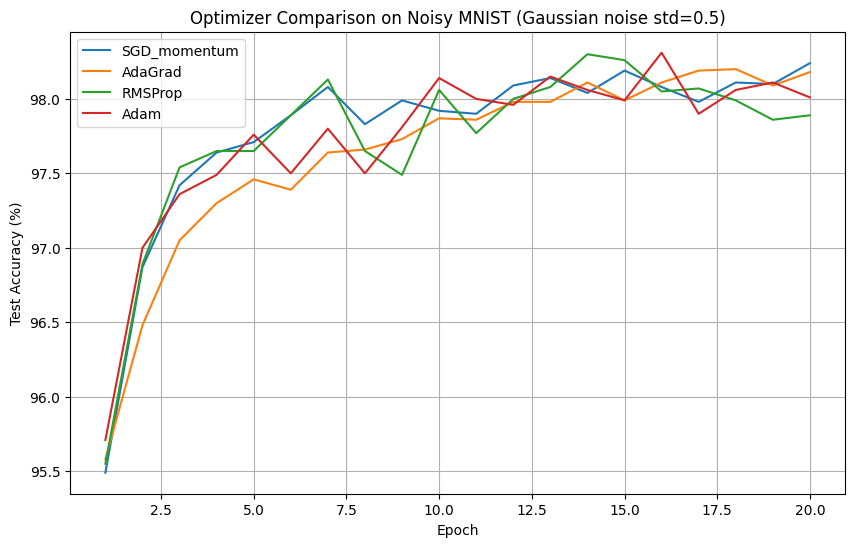


=== Final Test Accuracy after 20 epochs on Noisy MNIST ===
SGD_momentum   : 98.24%
AdaGrad        : 98.18%
RMSProp        : 97.89%
Adam           : 98.01%

=== Drop in Accuracy (clean → noisy) ===
SGD_momentum   : 98.14% → 98.24%  (drop = -0.10%)
AdaGrad        : 97.97% → 98.18%  (drop = -0.21%)
RMSProp        : 97.97% → 97.89%  (drop = 0.08%)
Adam           : 97.75% → 98.01%  (drop = -0.26%)

✅ Optimizer with smallest performance loss: Adam


In [40]:

# رسم نمودار دقت آزمون
plt.figure(figsize=(10,6))
for opt_name, accs in results.items():
	plt.plot(range(1, len(accs)+1), accs, label=opt_name)
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.title('Optimizer Comparison on Noisy MNIST (Gaussian noise std=0.5)')
plt.legend()
plt.grid(True)
plt.savefig('optimizers_noisy.png', dpi=150)
plt.show()

# گزارش دقت نهایی
print("\n=== Final Test Accuracy after 20 epochs on Noisy MNIST ===")
for opt_name, accs in results.items():
	print(f"{opt_name:15s}: {accs[-1]:.2f}%")


print("\n=== Drop in Accuracy (clean → noisy) ===")
drops = {}
for opt_name, clean_acc in clean_accs.items():
	noisy_acc = results[opt_name][-1]
	drop = clean_acc - noisy_acc
	drops[opt_name] = drop
	print(f"{opt_name:15s}: {clean_acc:.2f}% → {noisy_acc:.2f}%  (drop = {drop:.2f}%)")

# بهینه‌سازی که کمترین افت را دارد
best_robust = min(drops, key=drops.get)
print(f"\n✅ Optimizer with smallest performance loss: {best_robust}")


# برای اطمینان

3-4-3 ﻣﻘﺎﻳﺴﻪ ﺭﻭﻱ ﺩﺍﺩﻩ ﻱ ﻧﻮﻳﺰﻱ: ﺑﻪ ﺩﺍﺩﻩ ﻱ MNIST ﻧﻮﻳﺰ ﮔﺎﻭﺳﻲ ﺑﺎ ﺍﻧﺤﺮﺍﻑ 0.5 ﺍﺿﺎﻓﻪ ﻛﻨﻴﺪ. ﻣﺪﻝ ﺭﺍ ﺑﺎ ﺑﻬﺘﺮﻳﻦ ﭘﻴﻜﺮﺑﻨﺪﻱ ﻫﺮ ﺑﻬﻴﻨﻪ ﺳﺎﺯ ﺩﻭﺑﺎﺭﻩ ﺁﻣﻮﺯﺵ ﺩﻫﻴﺪ. ﻛﺪﺍﻡ ﺑﻬﻴﻨﻪ ﺳﺎﺯ ﻋﻤﻠﻜﺮﺩ ﺧﻮﺩ ﺭﺍ ﻛﻤﺘﺮ ﺍﺯ ﺩﺳﺖ میدهد؟

Using device: cuda

--- SGD_momentum on CLEAN data ---
Clean test accuracy: 98.19%
--- SGD_momentum on NOISY data ---
Noisy test accuracy: 98.19%

--- AdaGrad on CLEAN data ---
Clean test accuracy: 98.00%
--- AdaGrad on NOISY data ---
Noisy test accuracy: 98.07%

--- RMSProp on CLEAN data ---
Clean test accuracy: 97.83%
--- RMSProp on NOISY data ---
Noisy test accuracy: 98.16%

--- Adam on CLEAN data ---
Clean test accuracy: 97.59%
--- Adam on NOISY data ---
Noisy test accuracy: 98.16%

===== Final Results =====
Optimizer       Clean Acc (%)   Noisy Acc (%)   Drop (%)  
SGD_momentum    98.19           98.19           0.00      
AdaGrad         98.00           98.07           -0.07     
RMSProp         97.83           98.16           -0.33     
Adam            97.59           98.16           -0.57     

✅ Optimizer with smallest performance loss: Adam


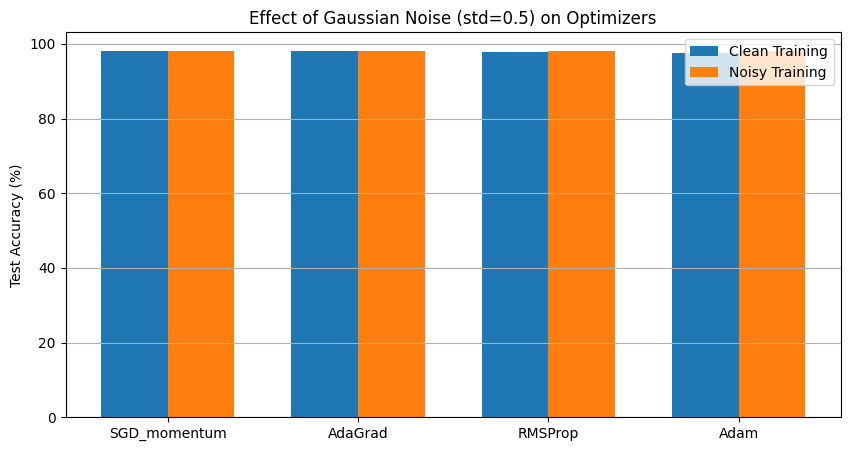

In [43]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------- مدل ثابت ----------------------------
class TwoLayerMLP(nn.Module):
    def __init__(self, input_dim=784, hidden1=128, hidden2=64, num_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.relu2 = nn.ReLU()
        self.out = nn.Linear(hidden2, num_classes)
    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.out(x)

# ---------------------------- دیتاست نویزی ----------------------------
class NoisyMNIST(Dataset):
    def __init__(self, dataset, noise_std=0.5):
        self.dataset = dataset
        self.noise_std = noise_std
    def __len__(self):
        return len(self.dataset)
    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        noise = torch.randn_like(img) * self.noise_std
        return img + noise, label

# ---------------------------- بارگذاری داده ----------------------------
def get_mnist_data_loaders(batch_size=64, noise_std=0.5, data_root=None):
    if data_root is None:
        data_root = Path.cwd() / 'data'   # یا مسیر مطلق خود را وارد کنید
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])
    trainset_clean = torchvision.datasets.MNIST(root=str(data_root), train=True,
                                                download=False, transform=transform)
    testset_clean = torchvision.datasets.MNIST(root=str(data_root), train=False,
                                               download=False, transform=transform)
    trainset_noisy = NoisyMNIST(trainset_clean, noise_std=noise_std)
    train_clean_loader = DataLoader(trainset_clean, batch_size=batch_size, shuffle=True)
    train_noisy_loader = DataLoader(trainset_noisy, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(testset_clean, batch_size=batch_size, shuffle=False)
    return train_clean_loader, train_noisy_loader, test_loader

# ---------------------------- تابع آموزش و ارزیابی ----------------------------
def train_and_eval(optimizer_name, lr, train_loader, test_loader, epochs=20, device='cuda'):
    model = TwoLayerMLP().to(device)
    criterion = nn.CrossEntropyLoss()
    if optimizer_name == 'SGD_momentum':
        opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    elif optimizer_name == 'AdaGrad':
        opt = optim.Adagrad(model.parameters(), lr=lr)
    elif optimizer_name == 'RMSProp':
        opt = optim.RMSprop(model.parameters(), lr=lr)
    elif optimizer_name == 'Adam':
        opt = optim.Adam(model.parameters(), lr=lr)
    else:
        raise ValueError('Unknown optimizer')
    
    test_accs = []
    for epoch in range(epochs):
        model.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            opt.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            opt.step()
        # ارزیابی
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, pred = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (pred == labels).sum().item()
        acc = 100.0 * correct / total
        test_accs.append(acc)
    return test_accs[-1]   # دقت نهایی

# ---------------------------- اجرای اصلی ----------------------------
def main():
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f"Using device: {device}")
    
    # مسیر داده را طبق سیستم خود تنظیم کنید (مثال: مسیر مطلق پوشه data)
    data_root = Path("D:/AUT/Courses/Deep Learning/DL HW/HW2/HW02-404131049/Bias-Variance, Regularization, Optimization, Normalization/data")
    batch_size = 64
    noise_std = 0.5
    
    train_clean_loader, train_noisy_loader, test_loader = get_mnist_data_loaders(
        batch_size=batch_size, noise_std=noise_std, data_root=data_root
    )
    
    # بهترین نرخ‌های یادگیری (از بخش قبل)
    best_lrs = {
        'SGD_momentum': 0.01,
        'AdaGrad': 0.01,
        'RMSProp': 0.001,
        'Adam': 0.001
    }
    
    results = {}
    for opt_name, lr in best_lrs.items():
        print(f"\n--- {opt_name} on CLEAN data ---")
        acc_clean = train_and_eval(opt_name, lr, train_clean_loader, test_loader, epochs=20, device=device)
        print(f"Clean test accuracy: {acc_clean:.2f}%")
        
        print(f"--- {opt_name} on NOISY data ---")
        acc_noisy = train_and_eval(opt_name, lr, train_noisy_loader, test_loader, epochs=20, device=device)
        print(f"Noisy test accuracy: {acc_noisy:.2f}%")
        
        results[opt_name] = {'clean': acc_clean, 'noisy': acc_noisy}
    
    # نمایش جدول و محاسبه افت
    print("\n===== Final Results =====")
    print(f"{'Optimizer':<15} {'Clean Acc (%)':<15} {'Noisy Acc (%)':<15} {'Drop (%)':<10}")
    drops = {}
    for opt_name, vals in results.items():
        drop = vals['clean'] - vals['noisy']
        drops[opt_name] = drop
        print(f"{opt_name:<15} {vals['clean']:<15.2f} {vals['noisy']:<15.2f} {drop:<10.2f}")
    
    best = min(drops, key=drops.get)
    print(f"\n✅ Optimizer with smallest performance loss: {best}")
    
    # رسم نمودار مقایسه
    plt.figure(figsize=(10,5))
    x = list(results.keys())
    clean_vals = [results[o]['clean'] for o in x]
    noisy_vals = [results[o]['noisy'] for o in x]
    width = 0.35
    plt.bar([i - width/2 for i in range(len(x))], clean_vals, width, label='Clean Training')
    plt.bar([i + width/2 for i in range(len(x))], noisy_vals, width, label='Noisy Training')
    plt.xticks(range(len(x)), x)
    plt.ylabel('Test Accuracy (%)')
    plt.title('Effect of Gaussian Noise (std=0.5) on Optimizers')
    plt.legend()
    plt.grid(True, axis='y')
    plt.savefig('noisy_comparison_fixed.png', dpi=150)
    plt.show()

if __name__ == "__main__":
    main()